# Does the soil treatment change snowpack water delivery?

Paired SNOWPACK 3.7.0 sensitivity experiments at PPSA, TRAM and HEEN: two lapse-rate forcings × base/soil. This notebook inherits site definitions, labels and the exact snow-disappearance function from `3_read_snowpack_output_compare_all_sites_lapserate_soil_figure.ipynb` **without executing or modifying that notebook**. Only the same 12 simulations are read. The user-preferred filename is `3_compare_snowpack_runoff_base_vs_soil.ipynb`.

**Response: snowpack outflow, not snowmelt production, infiltration, or catchment discharge.** Rain passing through snow is part of snowpack outflow. Bare-ground rain is explicitly excluded from the main response. Snow-base delivery and 5 m soil-bottom drainage are never added.

Primary seasonal window: **(March 1 00:00, September 1 00:00] UTC**, the same fixed spring/summer window in each base/soil pair. Supplementary water-year summaries use **(October 1 00:00, next October 1 00:00]**. Hourly fluxes are treated as preceding-interval totals. Partial water years are flagged even when the entire spring window is available. No missing flux is replaced with zero. First seasons remain initialization-sensitive; these idealized loam profiles are not site measurements.

In [1]:
from pathlib import Path
from io import StringIO
import ast, json, hashlib, configparser, subprocess, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display, Markdown

REPO = Path('/home/cassie/python/repos/snow_modeling_point')
MODEL_ROOT = Path('/home/cassie/python/models/run_snowpack/sites')
SOURCE_NOTEBOOK = REPO / 'sites/all_sites/3_read_snowpack_output_compare_all_sites_lapserate_soil_figure.ipynb'
OUT = REPO / 'figures/soil_runoff_comparison'
OUT.mkdir(parents=True, exist_ok=True)
source_nb = json.loads(SOURCE_NOTEBOOK.read_text())
wanted = {'SITE_CONFIG','FORCINGS','COLORS','LABELS','STYLES','SNOW_FREE_CM','SWE_FREE_KG_M2',
          'SNOW_FREE_DAYS','MIN_VALID_HOURS_PER_DAY','MIN_SEASON_PEAK_CM'}
for cell in source_nb['cells']:
    if cell['cell_type'] != 'code':
        continue
    tree = ast.parse(''.join(cell['source']))
    for node in tree.body:
        if isinstance(node, ast.Assign) and any(isinstance(t, ast.Name) and t.id in wanted for t in node.targets):
            exec(compile(ast.Module(body=[node], type_ignores=[]), str(SOURCE_NOTEBOOK), 'exec'))
        elif isinstance(node, ast.FunctionDef) and node.name == 'melt_out':
            exec(compile(ast.Module(body=[node], type_ignores=[]), str(SOURCE_NOTEBOOK), 'exec'))
assert len(SITE_CONFIG) == 3 and set(FORCINGS.values()) == {'hrrrak_lapserate','met_hrrrak_lapserate'}
LOW_VOLUME_MM = 50.0
PERCENT_DENOMINATOR_MM = 100.0
SNOW_EPS = 1e-6
LF_KJ_KG = 334.0
plt.rcParams.update({'font.size':10, 'axes.spines.top':False, 'axes.spines.right':False, 'figure.dpi':110})

def savefig(fig, name):
    for ext in ('png','pdf'):
        fig.savefig(OUT / f'{name}.{ext}', dpi=300, bbox_inches='tight')

version = subprocess.run(['snowpack','--version'],capture_output=True,text=True,check=True)
metadata=dict(source_notebook=str(SOURCE_NOTEBOOK),source_notebook_sha256=hashlib.sha256(SOURCE_NOTEBOOK.read_bytes()).hexdigest(),
              snowpack_version=(version.stdout+version.stderr).strip(),python=sys.version,pandas=pd.__version__,numpy=np.__version__,
              spring_window='(Mar 1 00:00, Sep 1 00:00] UTC',area='horizontal projected',interval_hours=1)
(OUT/'analysis_metadata.json').write_text(json.dumps(metadata,indent=2))
print(metadata['snowpack_version'])


Snowpack version 3.7.0 compiled on Apr 29 2024 14:06:49
	Libsnowpack 3.7.0 compiled on Apr 29 2024 14:04:24
	MeteoIO 2.11.0 compiled on Apr 26 2024 14:12:50


## Version-specific definitions and area convention

Checked against the installed headers and version-matched release source, not field names alone:

- [`SmetIO.cc`](https://code.wsl.ch/snow-models/snowpack/-/blob/Snowpack-3.7.0/snowpack/plugins/SmetIO.cc), mass output: `MS_SN_Runoff` is the snow-base virtual lysimeter. `SWE`, `MS_Water`, `MS_Water_Soil`, `MS_Ice_Soil`, snow outflow, surface mass flux, soil-bottom drainage, sublimation, evaporation and erosion are already divided by cos(slope) on output: **horizontal projected area**. Do not divide these again. All these sites retain slope 38°.
- [`Main.cc`](https://code.wsl.ch/snow-models/snowpack/-/blob/Snowpack-3.7.0/applications/snowpack/Main.cc), precipitation projection and output: precipitation is projected onto slope area internally; the `MS_Rain` and `MS_Snow` output branches do **not** divide by cosine. For horizontal mm, integrate their rates over the hour and divide by cos(38°). The stored `PRECIP_RATES=true`, `AVGSUM_TIME_SERIES=true`, `CUMSUM_MASS=false`, 60-minute calculation step and hourly output are verified below. 1 kg/m² water = 1 mm water equivalent. Output is research-mode interval mass, not cumulative runoff or a runoff rate requiring a second 3600 factor.
- [`WaterTransport.cc`](https://code.wsl.ch/snow-models/snowpack/-/blob/Snowpack-3.7.0/snowpack/snowpackCore/WaterTransport.cc), `compTransportMass`: in the no-snow/no-soil branch, rain is booked to rain, soil-bottom bookkeeping and surface mass flux, **not** snowpack outflow. With soil and no snow, rain is included in surface input. [`ReSolver1d.cc`](https://code.wsl.ch/snow-models/snowpack/-/blob/Snowpack-3.7.0/snowpack/snowpackCore/ReSolver1d.cc) distinguishes snow/soil interface flux from bottom flux. Snow uses BUCKET in all these runs; soil uses Richards only in soil runs.
- [`DataClasses.cc`](https://code.wsl.ch/snow-models/snowpack/-/blob/Snowpack-3.7.0/snowpack/DataClasses.cc), `compSnowpackInternalEnergyChange`, sums **snow elements only**, while soil phase changes are separate. `meltFreezeEnergySnow` is written as interval **kJ/m² of slope area**, despite its misleading `plot_unit` header label W/m². Dividing by 334 kJ/kg and cosine gives signed net snow phase-change equivalent in horizontal mm: positive melting, negative refreezing. It is **not gross melt production**: simultaneous melt/refreeze within an hour can cancel.
- In `Main.cc` negative `MS_Wind` denotes a **potential erosion index**, not actual deposition. It is retained in the field audit but excluded from physical mass gain; positive values represent actual erosion loss.
- `MS_Surface_Mass_Flux` is a signed surface boundary accounting diagnostic, including bare-ground rain and some vapor terms. It is **not a measured overland-runoff hydrograph**. `MS_Soil_Runoff` is soil-bottom drainage at 5 m along the modeled column (~6.35 m vertically on these slopes); it may include antecedent soil water.

The available interval starts/ends cannot resolve rain versus melt within the final hour of disappearance. An interval is snow-associated if SWE or depth is positive at **either endpoint**, or if actual modeled new snowfall is positive within the interval, retaining the final drainage hour and any rain during that hour. The new-snow condition also retains short-lived snow deposited and melted entirely within an hour; zero SWE at both endpoints is not sufficient to discard that outflow. Known snow-free intervals are zeroed by classification only when runoff itself is present; unknown/missing runoff stays missing. Raw and excluded amounts are audited. No water is labeled snowmelt merely because it leaves a snow-covered column.

In [2]:
FIELDS = ['HS_mod','SWE','MS_SN_Runoff','MS_Rain','MS_Snow','MS_Water','MS_Water_Soil','MS_Ice_Soil',
          'MS_Soil_Runoff','MS_Surface_Mass_Flux','MS_Sublimation','MS_Evap','MS_Wind',
          'meltFreezeEnergySnow','meltFreezeEnergySoil','TSG','Lateral_flow_snow','Lateral_flow_soil']

def read_ini(path):
    cfg = configparser.ConfigParser(interpolation=None, delimiters=('=',), inline_comment_prefixes=(';','#'), strict=False)
    cfg.read(path)
    return {(s.upper(), k.upper()):v for s in cfg.sections() for k,v in cfg[s].items()}

def read_run(path):
    header = {}
    with path.open() as stream:
        for line in stream:
            line = line.strip()
            if line == '[DATA]': break
            if '=' in line and not line.startswith('#'):
                key,value = line.split('=',1); header[key.strip()] = value.strip()
        else: raise ValueError(f'No data section: {path}')
        names = header['fields'].split()
        raw = pd.read_csv(stream, sep=r'\s+', names=names)
    cfg = read_ini(path.with_suffix('.ini'))
    time = pd.DatetimeIndex(pd.to_datetime(raw.pop('timestamp'), utc=True)).tz_convert(None)
    if float(header['tz']) != 0: raise ValueError('Expected UTC SMET: '+str(path))
    duplicates = int(time.duplicated().sum())
    if duplicates or not time.is_monotonic_increasing: raise ValueError('Duplicate/unsorted timestamps: '+str(path))
    raw.index = time
    raw = raw.replace(float(header.get('nodata',-999)), np.nan)
    mult, offset = np.array(header['units_multiplier'].split(),float), np.array(header['units_offset'].split(),float)
    assert len(mult)==len(offset)==len(names)
    converted = pd.DataFrame(index=time)
    field_rows = []
    for field in FIELDS:
        if field in raw:
            i=names.index(field); converted[field]=raw[field]*mult[i]+offset[i]
            field_rows.append(dict(field=field, raw_plot_unit=header['plot_unit'].split()[i],
                                   multiplier=mult[i],offset=offset[i],missing_values=int(raw[field].isna().sum()),available=True))
        else:
            converted[field]=np.nan
            field_rows.append(dict(field=field,available=False,missing_values=len(raw)))
    step=float(cfg[('SNOWPACK','CALCULATION_STEP_LENGTH')])/60
    output_step=float(cfg[('OUTPUT','TS_DAYS_BETWEEN')])*24
    assert abs(step-1)<1e-6 and abs(output_step-1)<1e-5
    assert cfg[('OUTPUT','CUMSUM_MASS')].lower()=='false', 'Cumulative run needs explicit reset handling'
    assert cfg[('OUTPUT','PRECIP_RATES')].lower()=='true'
    assert cfg[('OUTPUT','AVGSUM_TIME_SERIES')].lower()=='true'
    assert cfg[('SNOWPACKADVANCED','PERP_TO_SLOPE')].lower()=='false'
    cosine=np.cos(np.deg2rad(float(header['slope_angle'])))
    converted['HS_cm']=converted.HS_mod*100
    converted['outflow_raw_mm']=converted.MS_SN_Runoff  # already horizontal interval kg/m2
    converted['rain_mm']=converted.MS_Rain*step/cosine
    converted['snowfall_mm']=converted.MS_Snow*step/cosine
    converted['erosion_mm']=converted.MS_Wind.clip(lower=0)*step  # SmetIO already divides by cosine
    converted['net_snow_phase_mm']=converted.meltFreezeEnergySnow/LF_KJ_KG/cosine
    converted['ground_T_C']=converted.TSG-273.15
    current=(converted.SWE>SNOW_EPS)|(converted.HS_cm>SNOW_EPS)
    previous=current.shift(1)
    adjacent=time.to_series().diff().eq(pd.Timedelta(hours=1)).to_numpy()
    previous=previous.where(adjacent)
    # Unknown initial history remains unknown unless snow is present at the current endpoint.
    ephemeral_snow=converted.MS_Snow.gt(SNOW_EPS)
    mask=(current | previous.eq(True) | ephemeral_snow).astype('boolean')
    unknown=(previous.isna() & ~current & ~ephemeral_snow) | converted[['SWE','HS_cm']].isna().any(axis=1)
    mask=mask.mask(unknown)
    converted['snow_interval']=mask
    converted['outflow_mm']=converted.outflow_raw_mm.where(mask.fillna(False),0).where(converted.outflow_raw_mm.notna() & mask.notna())
    for a,b in [('rain_mm','rain_on_snow_mm'),('MS_Evap','snow_evap_signed_mm'),('MS_Sublimation','snow_subl_signed_mm')]:
        converted[b]=converted[a].where(mask.fillna(False),0).where(converted[a].notna() & mask.notna())
    dt=time.to_series().diff()
    audit=dict(file=path.name, start_UTC=time.min(),end_UTC=time.max(),records=len(time),duplicates=duplicates,
        nonhourly_steps=int(dt.iloc[1:].ne(pd.Timedelta(hours=1)).sum()),timezone=header['tz'],slope_deg=float(header['slope_angle']),
        cumulative=False,cumulative_resets='not applicable: interval output, CUMSUM_MASS=false',
        negative_outflow_intervals=int((converted.outflow_raw_mm < 0).sum()),
        negative_potential_erosion_intervals=int(converted.MS_Wind.lt(0).sum()),
        snow_precip_input_area='slope-normal, divided by cosine here',
        decreases_in_raw_outflow=int(converted.outflow_raw_mm.diff().lt(0).sum()),
        snowfree_raw_outflow_mm=converted.outflow_raw_mm.where(mask.eq(False)).sum(min_count=1),
        transient_snow_outflow_mm=converted.outflow_raw_mm.where(~current & previous.eq(False) & ephemeral_snow).sum(min_count=1),
        final_drainage_mm=converted.outflow_raw_mm.where(~current & previous.eq(True)).sum(min_count=1),
        bare_ground_rain_mm=converted.rain_mm.where(mask.eq(False)).sum(min_count=1),
        source_sha256=hashlib.sha256(path.read_bytes()).hexdigest(),settings_sha256=hashlib.sha256(path.with_suffix('.ini').read_bytes()).hexdigest())
    return converted,header,cfg,audit,field_rows

runs,headers,settings,audit_rows,field_rows={}, {}, {}, [], []
for site,conf in SITE_CONFIG.items():
    for forcing,prefix in FORCINGS.items():
        for experiment in ('base','soil'):
            key=(site,forcing,experiment)
            path=MODEL_ROOT/site/'output'/f'{prefix}_{site}_{conf[forcing]}_{experiment}.smet'
            runs[key],headers[key],settings[key],audit,fields=read_run(path)
            audit_rows.append(dict(site=site,forcing=forcing,experiment=experiment,**audit))
            field_rows.extend(dict(site=site,forcing=forcing,experiment=experiment,**f) for f in fields)
audit=pd.DataFrame(audit_rows); field_audit=pd.DataFrame(field_rows)
audit.to_csv(OUT/'run_audit.csv',index=False);field_audit.to_csv(OUT/'field_audit.csv',index=False)
setting_rows=[]
for key,cfg in settings.items():
    for section,name in [('OUTPUT','CUMSUM_MASS'),('OUTPUT','PRECIP_RATES'),('OUTPUT','AVGSUM_TIME_SERIES'),
                         ('OUTPUT','TS_DAYS_BETWEEN'),('SNOWPACK','CALCULATION_STEP_LENGTH'),
                         ('SNOWPACKADVANCED','PERP_TO_SLOPE'),('SNOWPACKADVANCED','WATERTRANSPORTMODEL_SNOW'),
                         ('SNOWPACKADVANCED','WATERTRANSPORTMODEL_SOIL')]:
        setting_rows.append(dict(site=key[0],forcing=key[1],experiment=key[2],section=section,key=name,value=cfg.get((section,name),'not written')))
pd.DataFrame(setting_rows).to_csv(OUT/'run_settings.csv',index=False)
display(audit.drop(columns=['source_sha256','settings_sha256','cumulative_resets']))
display(field_audit.loc[~field_audit.available])
print('Raw decreases are expected for interval fluxes; they are not cumulative resets.')


,site,forcing,experiment,file,start_UTC,end_UTC,records,duplicates,nonhourly_steps,timezone,slope_deg,cumulative,negative_outflow_intervals,negative_potential_erosion_intervals,snow_precip_input_area,decreases_in_raw_outflow,snowfree_raw_outflow_mm,transient_snow_outflow_mm,final_drainage_mm,bare_ground_rain_mm
0,ppsa,hrrr,base,hrrrak_lapserate_ppsa_WY2020-WY2025_base.smet,2019-10-01 05:00:00,2025-09-01 00:00:00,51884,0,0,0,38.0,False,0,3293,"slope-normal, divided by cosine here",6130,0.0,NaN,35.535,5787.776346
1,ppsa,hrrr,soil,hrrrak_lapserate_ppsa_WY2020-WY2025_soil.smet,2019-10-01 06:00:00,2025-09-01 00:00:00,51883,0,0,0,38.0,False,0,3294,"slope-normal, divided by cosine here",7805,0.0,11.400,34.846,6259.983100
2,ppsa,mixed,base,met_hrrrak_lapserate_ppsa_WY2020-WY2025_base.smet,2019-10-01 06:00:00,2025-09-01 00:00:00,51883,0,0,0,38.0,False,0,3038,"slope-normal, divided by cosine here",5969,0.0,NaN,30.116,6568.549955
3,ppsa,mixed,soil,met_hrrrak_lapserate_ppsa_WY2020-WY2025_soil.smet,2019-10-01 06:00:00,2025-09-01 00:00:00,51883,0,0,0,38.0,False,0,3011,"slope-normal, divided by cosine here",7891,0.0,5.209,45.073,6858.136104
4,tram,hrrr,base,hrrrak_lapserate_tram_WY2020-WY2025_base.smet,2019-10-01 05:00:00,2025-09-01 00:00:00,51884,0,0,0,38.0,False,0,6445,"slope-normal, divided by cosine here",6941,0.0,NaN,57.430,9160.621181
5,tram,hrrr,soil,hrrrak_lapserate_tram_WY2020-WY2025_soil.smet,2019-10-01 06:00:00,2025-09-01 00:00:00,51883,0,0,0,38.0,False,0,6429,"slope-normal, divided by cosine here",7669,0.0,7.680,51.135,9754.465868
6,tram,mixed,base,met_hrrrak_lapserate_tram_WY2023-WY2025_base.smet,2022-10-01 06:00:00,2025-09-01 00:00:00,25579,0,0,0,38.0,False,0,2605,"slope-normal, divided by cosine here",2629,0.0,NaN,16.349,4166.359387
7,tram,mixed,soil,met_hrrrak_lapserate_tram_WY2023-WY2025_soil.smet,2022-10-01 06:00:00,2025-09-01 00:00:00,25579,0,0,0,38.0,False,0,2594,"slope-normal, divided by cosine here",2794,0.0,4.361,25.082,4367.083805
8,heen,hrrr,base,hrrrak_lapserate_heen_WY2020-WY2025_base.smet,2019-10-01 06:00:00,2025-09-01 00:00:00,51883,0,0,0,38.0,False,0,3054,"slope-normal, divided by cosine here",5007,0.0,NaN,25.386,6854.614579
9,heen,hrrr,soil,hrrrak_lapserate_heen_WY2020-WY2025_soil.smet,2019-10-01 06:00:00,2025-09-01 00:00:00,51883,0,0,0,38.0,False,0,3075,"slope-normal, divided by cosine here",5417,0.0,4.749,37.196,7318.145055


,site,forcing,experiment,field,raw_plot_unit,multiplier,offset,missing_values,available
14,ppsa,hrrr,base,meltFreezeEnergySoil,NaN,NaN,NaN,51884,False
16,ppsa,hrrr,base,Lateral_flow_snow,NaN,NaN,NaN,51884,False
17,ppsa,hrrr,base,Lateral_flow_soil,NaN,NaN,NaN,51884,False
50,ppsa,mixed,base,meltFreezeEnergySoil,NaN,NaN,NaN,51883,False
52,ppsa,mixed,base,Lateral_flow_snow,NaN,NaN,NaN,51883,False
53,ppsa,mixed,base,Lateral_flow_soil,NaN,NaN,NaN,51883,False
86,tram,hrrr,base,meltFreezeEnergySoil,NaN,NaN,NaN,51884,False
88,tram,hrrr,base,Lateral_flow_snow,NaN,NaN,NaN,51884,False
89,tram,hrrr,base,Lateral_flow_soil,NaN,NaN,NaN,51884,False
122,tram,mixed,base,meltFreezeEnergySoil,NaN,NaN,NaN,25579,False


Raw decreases are expected for interval fluxes; they are not cumulative resets.


## Paired windows and metrics

All available water years are listed. Flux totals and timing metrics require every expected hourly interval within the selected window; a partial-known sum and coverage are reported separately, never promoted to a complete total. The first simulated season of either member is flagged. Spring timing is withheld below 50 mm seasonal outflow or when negative/missing fluxes prevent a meaningful monotone cumulative curve. Percent changes require base volume ≥100 mm; mm and days remain primary.

T10/T50/T90 are the **earliest interval end** at which the cumulative total reaches each fraction (no interpolation). T10–T90 duration is in days. The 24-hour peak uses 24 consecutive hourly interval totals, wholly inside the seasonal window; exact ties select the earliest ending timestamp. Snow disappearance uses the source notebook's daily, sustained snow-free criterion unchanged. Spring dates and water-year completeness are separate: the final 2025 September is partial but its March–August window is complete.

Availability limits: the complete main `MS_SN_Runoff` response is present in all 12 files. Base runs have no soil column: their soil-bottom drainage is nodata, not zero drainage or measured infiltration. Some lateral diagnostics are absent or nodata depending on water-transport domain. `field_audit.csv` distinguishes absent fields from present fields with missing values; those runs still support the snowpack-outflow comparison, but not a base-versus-soil comparison of deep drainage.


In [3]:
pairs={}
for site in SITE_CONFIG:
    for forcing in FORCINGS:
        a,b=runs[(site,forcing,'base')],runs[(site,forcing,'soil')]
        start,end=max(a.index.min(),b.index.min()),min(a.index.max(),b.index.max())
        expected=pd.date_range(start,end,freq='h')
        # Reindexing exposes gaps; it never imputes a flux.
        pairs[(site,forcing)]={e:runs[(site,forcing,e)].reindex(expected) for e in ('base','soil')}

def bounds(wy,window):
    return (pd.Timestamp(wy,3,1),pd.Timestamp(wy,9,1)) if window=='spring' else (pd.Timestamp(wy-1,10,1),pd.Timestamp(wy,10,1))

def summarize(q,lo,hi):
    index=pd.date_range(lo+pd.Timedelta(hours=1),hi,freq='h')
    q=q.reindex(index)
    complete=bool(q.notna().all())
    known=q.sum(min_count=1)
    total=known if complete else np.nan
    valid=complete and total>=LOW_VOLUME_MM and not q.lt(0).any()
    r=dict(expected_hours=len(q),valid_hours=int(q.notna().sum()),complete=complete,known_total_mm=known,
           total_mm=total,low_volume=bool(complete and total<LOW_VOLUME_MM),timing_valid=valid)
    for pct in (10,50,90):
        r[f't{pct}']=q.cumsum().ge(total*pct/100).idxmax() if valid else pd.NaT
    r['duration_10_90_days']=(r['t90']-r['t10']).total_seconds()/86400 if valid else np.nan
    rolling=q.rolling(24,min_periods=24).sum()
    r['peak24_mm']=rolling.max() if complete else np.nan
    r['peak24_end']=rolling.idxmax() if complete and rolling.notna().any() else pd.NaT
    return r

metric_rows=[]
for (site,forcing),pair in pairs.items():
    index=pair['base'].index
    wy_values=index.year+(index.month>=10)
    first_wy=int(wy_values.min())
    for wy in range(first_wy,int(wy_values.max())+1):
        wlo,whi=bounds(wy,'water_year')
        expected_wy=pd.date_range(wlo+pd.Timedelta(hours=1),whi,freq='h')
        wy_complete=all(pair[e].outflow_mm.reindex(expected_wy).notna().all() for e in ('base','soil'))
        dates={}
        for e in ('base','soil'):
            d=pair[e]; old_group=d.loc[(d.index.year+(d.index.month>=10))==wy]
            dates[e],_=melt_out(old_group.HS_cm,old_group.SWE)
        for window in ('spring','water_year'):
            lo,hi=bounds(wy,window)
            row=dict(site=site,forcing=forcing,water_year=wy,window=window,start_exclusive_UTC=lo,end_inclusive_UTC=hi,
                     initialization_sensitive=wy==first_wy,incomplete_water_year=not wy_complete)
            for e in ('base','soil'):
                stats=summarize(pair[e].outflow_mm,lo,hi)
                row[f'{e}_SWE_at_window_start_mm']=pair[e].SWE.reindex([lo]).iloc[0]
                row[f'{e}_SWE_at_window_end_mm']=pair[e].SWE.reindex([hi]).iloc[0]
                row.update({f'{e}_{k}':v for k,v in stats.items()})
                row[f'{e}_disappearance']=dates[e]
                idx=pd.date_range(lo+pd.Timedelta(hours=1),hi,freq='h')
                d=pair[e].reindex(idx)
                row[f'{e}_unmasked_SN_Runoff_known_mm']=d.outflow_raw_mm.sum(min_count=1)
                row[f'{e}_snowfree_rain_known_mm']=d.rain_mm.where(d.snow_interval.eq(False)).sum(min_count=1)
            row['paired_complete']=row['base_complete'] and row['soil_complete']
            row['delta_total_mm']=row['soil_total_mm']-row['base_total_mm']
            row['delta_peak24_mm']=row['soil_peak24_mm']-row['base_peak24_mm']
            for key in ('t10','t50','t90','peak24_end','disappearance'):
                a,b=row[f'base_{key}'],row[f'soil_{key}']
                row[f'delta_{key}_days']=(b-a).total_seconds()/86400 if pd.notna(a) and pd.notna(b) else np.nan
            row['delta_duration_10_90_days']=row['soil_duration_10_90_days']-row['base_duration_10_90_days']
            row['delta_total_percent']=100*row['delta_total_mm']/row['base_total_mm'] if row['paired_complete'] and row['base_total_mm']>=PERCENT_DENOMINATOR_MM else np.nan
            metric_rows.append(row)
metrics=pd.DataFrame(metric_rows)
metrics.to_csv(OUT/'seasonal_metrics.csv',index=False)
spring=metrics[metrics.window.eq('spring')].copy()
display(spring[['site','forcing','water_year','initialization_sensitive','incomplete_water_year','paired_complete',
                'base_total_mm','soil_total_mm','delta_total_mm','delta_t50_days','delta_peak24_mm','delta_disappearance_days']].round(2))


,site,forcing,water_year,initialization_sensitive,incomplete_water_year,paired_complete,base_total_mm,soil_total_mm,delta_total_mm,delta_t50_days,delta_peak24_mm,delta_disappearance_days
0,ppsa,hrrr,2020,True,True,True,1996.88,1885.12,-111.76,-0.83,-0.37,-7.0
2,ppsa,hrrr,2021,False,False,True,2216.57,2183.20,-33.37,-0.96,-0.07,-6.0
4,ppsa,hrrr,2022,False,False,True,2242.89,2096.34,-146.55,-1.88,-1.50,-6.0
6,ppsa,hrrr,2023,False,False,True,2098.49,2002.46,-96.02,-2.12,-0.11,-8.0
8,ppsa,hrrr,2024,False,False,True,1499.30,1443.12,-56.17,-1.92,0.17,-5.0
10,ppsa,hrrr,2025,False,True,True,1636.38,1467.17,-169.21,-2.83,-3.10,-9.0
12,ppsa,mixed,2020,True,True,True,2046.37,1928.39,-117.98,-1.08,-0.39,-6.0
14,ppsa,mixed,2021,False,False,True,2100.74,2087.78,-12.96,-0.96,0.74,-6.0
16,ppsa,mixed,2022,False,False,True,1728.34,1675.39,-52.95,-0.58,-0.76,-4.0
18,ppsa,mixed,2023,False,False,True,2314.83,2179.79,-135.04,-3.17,-1.42,-8.0


## A · Cumulative spring snowpack outflow

Cumulative **mm over horizontal area**, not a normalized cumulative fraction. A flat snow-free segment means no classified snowpack outflow, not missing data imputed to zero. Both forcings retain their actual historical coverage; absent mixed-forcing years are not synthesized. Solid = base, dashed = soil. Each panel spans March–August of its labeled water year.

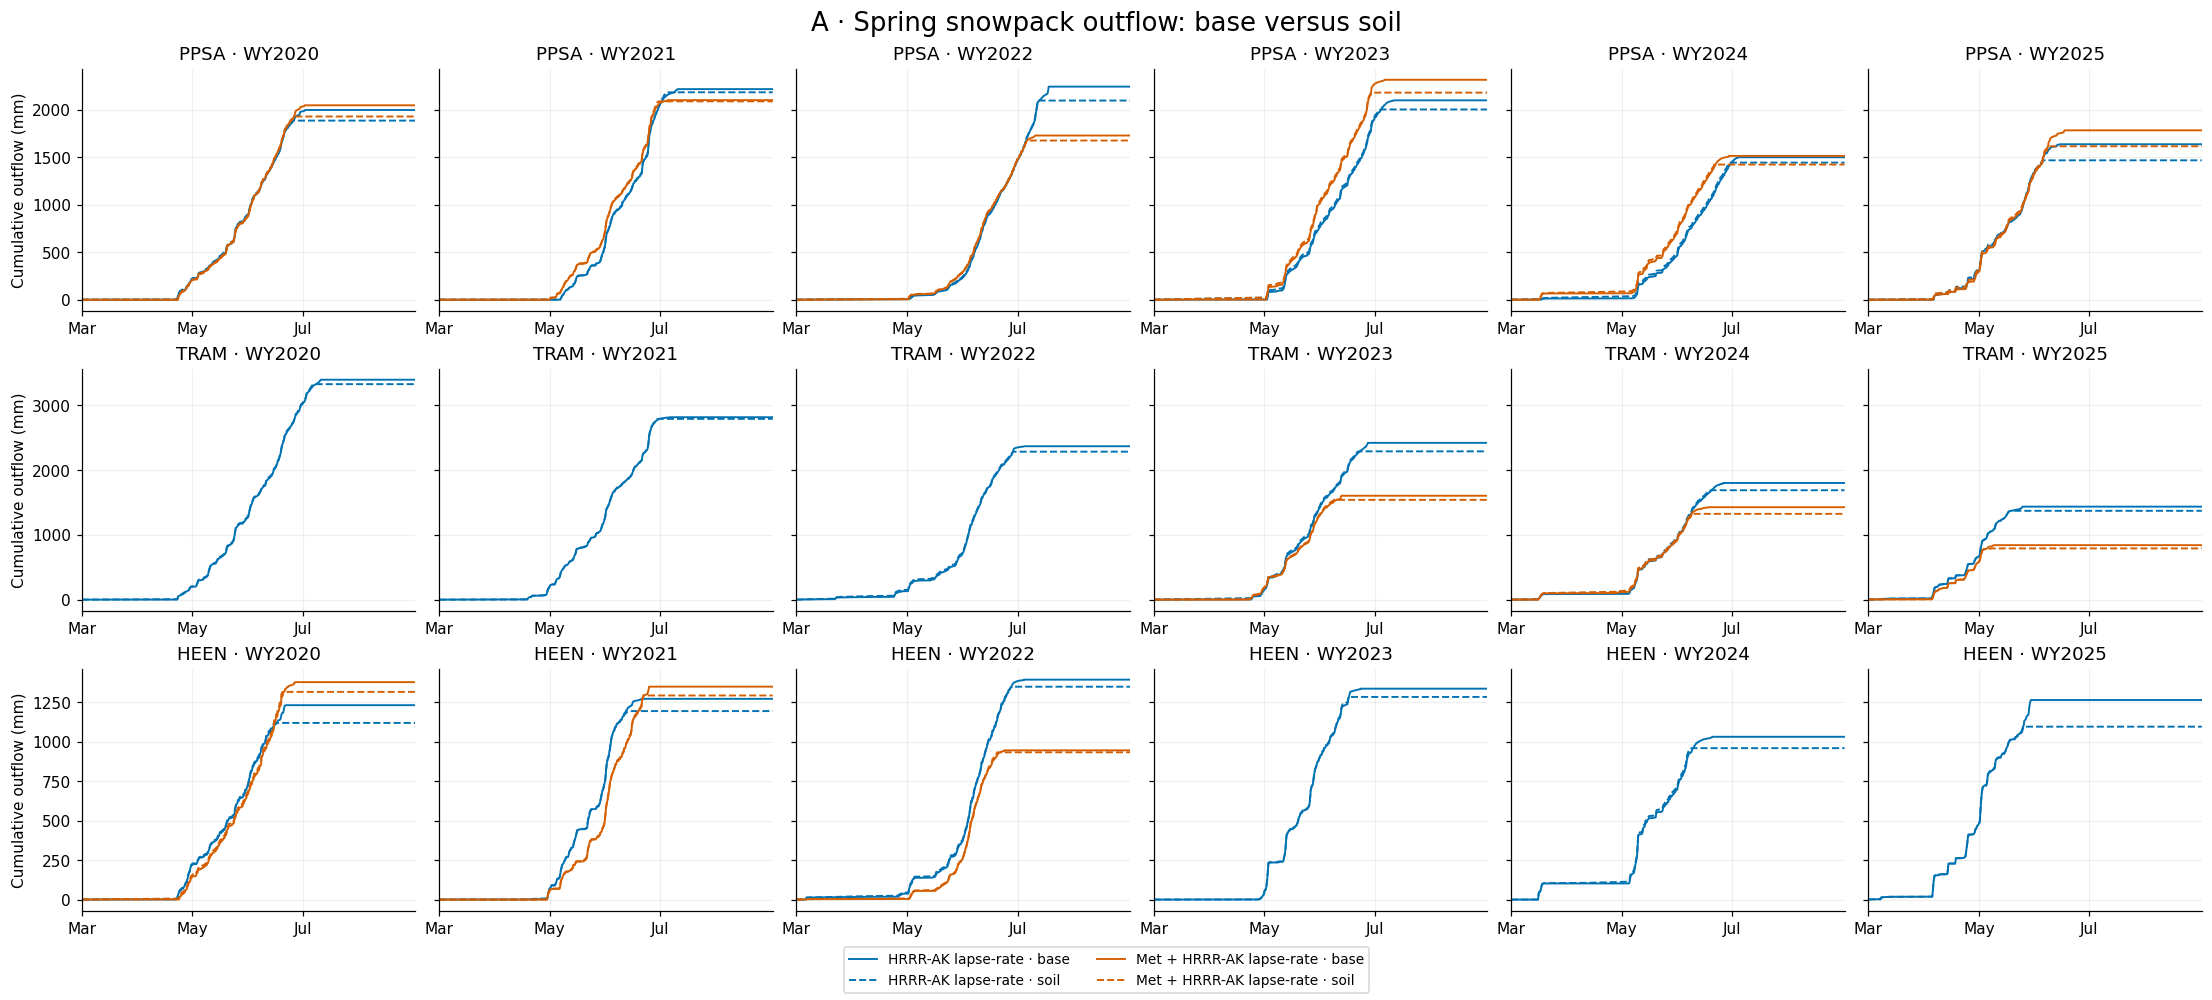

In [4]:
fig,axes=plt.subplots(3,6,figsize=(20,9),sharey='row',layout='constrained')
for i,(site,conf) in enumerate(SITE_CONFIG.items()):
    for j,wy in enumerate(range(2020,2026)):
        ax=axes[i,j];lo,hi=bounds(wy,'spring')
        for forcing in FORCINGS:
            for e in ('base','soil'):
                d=pairs[(site,forcing)][e]
                if d.index.max()<=lo or d.index.min()>=hi: continue
                q=d.outflow_mm.reindex(pd.date_range(lo+pd.Timedelta(hours=1),hi,freq='h'))
                ax.plot(q.index,q.cumsum(skipna=False),color=COLORS[forcing],ls=STYLES[e],lw=1.25,label=f'{LABELS[forcing]} · {e}')
        ax.set(title=f'{site.upper()} · WY{wy}',xlim=(lo,hi))
        ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[3,5,7]));ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
        ax.grid(alpha=.2)
        if j==0:ax.set_ylabel('Cumulative outflow (mm)')
handles,labels=axes[0,0].get_legend_handles_labels()
fig.legend(handles,labels,loc='outside lower center',ncol=2,fontsize=9)
fig.suptitle('A · Spring snowpack outflow: base versus soil',fontsize=17)
savefig(fig,'A_cumulative_spring_outflow');plt.show()


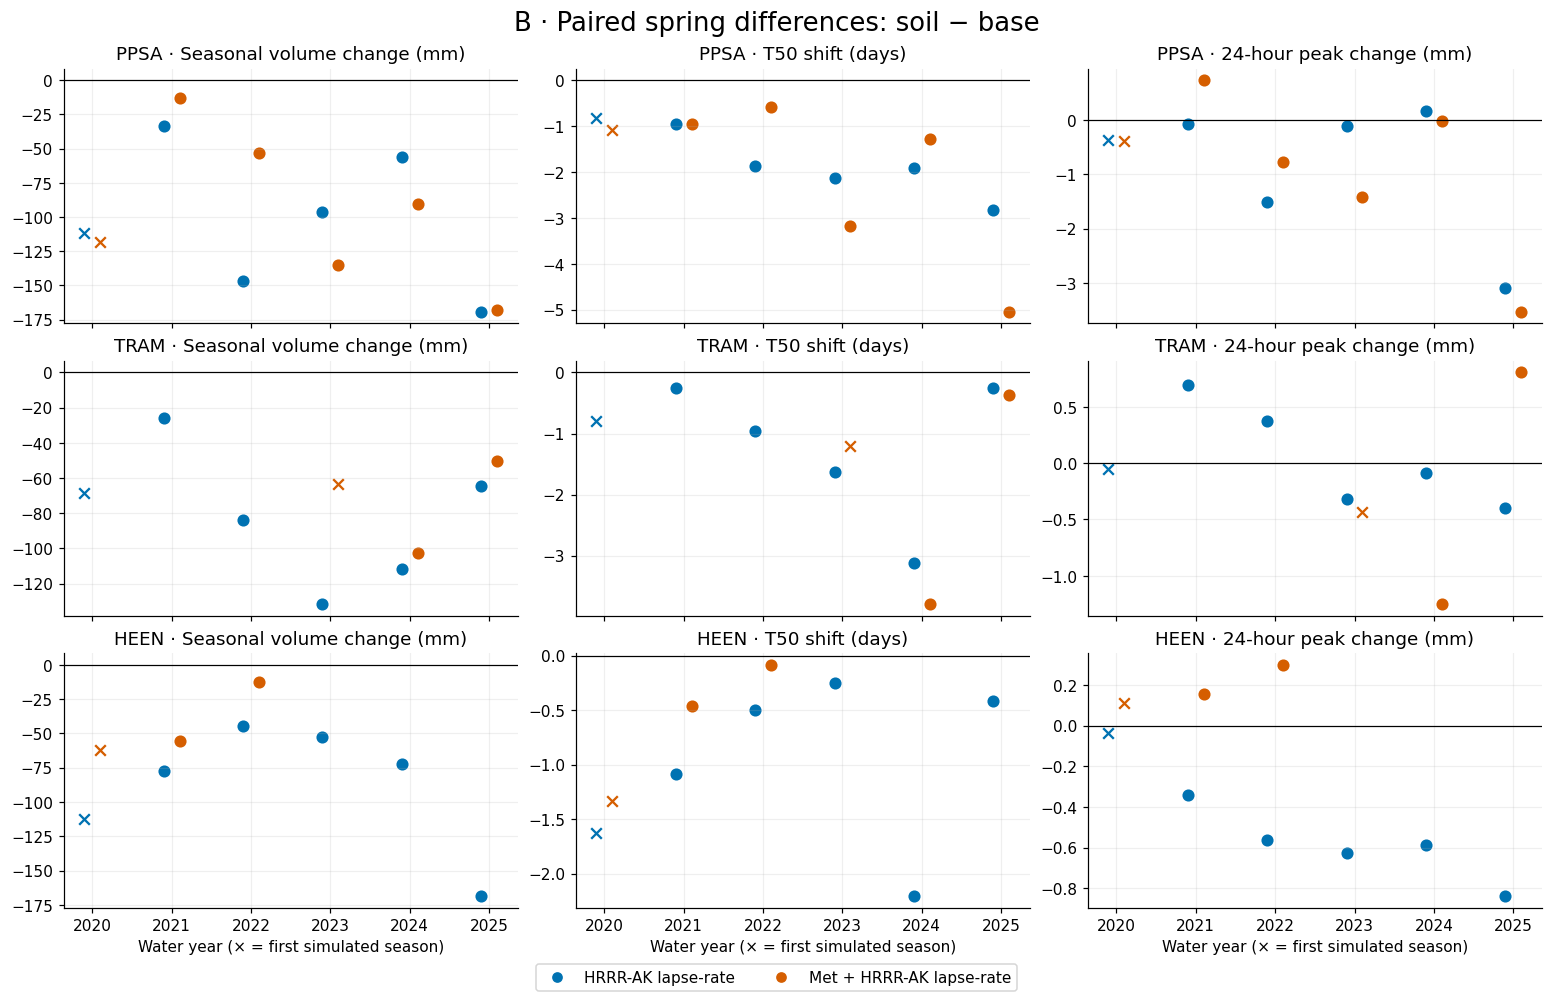

In [5]:
fig,axes=plt.subplots(3,3,figsize=(14,9),sharex=True,layout='constrained')
columns=[('delta_total_mm','Seasonal volume change (mm)'),('delta_t50_days','T50 shift (days)'),('delta_peak24_mm','24-hour peak change (mm)')]
for i,site in enumerate(SITE_CONFIG):
    for j,(column,label) in enumerate(columns):
        ax=axes[i,j]
        for offset,forcing in zip([-.10,.10],FORCINGS):
            rows=spring[(spring.site==site)&(spring.forcing==forcing)&spring.paired_complete]
            for _,r in rows.iterrows():
                ax.scatter(r.water_year+offset,r[column],s=48,color=COLORS[forcing],marker='x' if r.initialization_sensitive else 'o')
            ax.plot([],[],color=COLORS[forcing],marker='o',ls='',label=LABELS[forcing])
        ax.axhline(0,color='black',lw=.8);ax.grid(alpha=.2);ax.set(title=f'{site.upper()} · {label}',xticks=range(2020,2026))
        if i==2:ax.set_xlabel('Water year (× = first simulated season)')
handles,labels=axes[0,0].get_legend_handles_labels();fig.legend(handles,labels,loc='outside lower center',ncol=2)
fig.suptitle('B · Paired spring differences: soil − base',fontsize=17)
savefig(fig,'B_paired_seasonal_differences');plt.show()


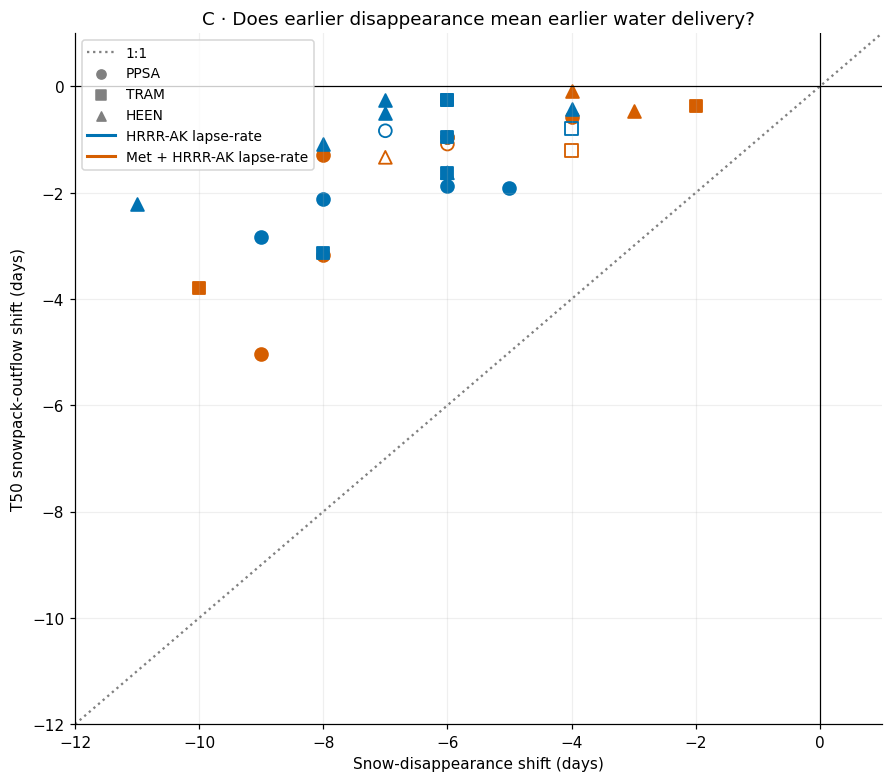

In [6]:
fig,ax=plt.subplots(figsize=(8,7),layout='constrained')
markers={'ppsa':'o','tram':'s','heen':'^'}
plot=spring.dropna(subset=['delta_disappearance_days','delta_t50_days'])
for _,r in plot.iterrows():
    ax.scatter(r.delta_disappearance_days,r.delta_t50_days,edgecolors=COLORS[r.forcing],marker=markers[r.site],s=70,
               facecolors='none' if r.initialization_sensitive else COLORS[r.forcing],linewidths=1.2)
limits=[min(-1.,plot[['delta_disappearance_days','delta_t50_days']].min().min()-1),
        max(1.,plot[['delta_disappearance_days','delta_t50_days']].max().max()+1)]
ax.plot(limits,limits,color='gray',ls=':',label='1:1');ax.axhline(0,color='black',lw=.8);ax.axvline(0,color='black',lw=.8)
for site,marker in markers.items():ax.scatter([],[],color='gray',marker=marker,label=site.upper())
for forcing in FORCINGS:ax.plot([],[],color=COLORS[forcing],lw=2,label=LABELS[forcing])
ax.set(xlabel='Snow-disappearance shift (days)',ylabel='T50 snowpack-outflow shift (days)',xlim=limits,ylim=limits,
       title='C · Does earlier disappearance mean earlier water delivery?')
ax.legend(fontsize=9,loc='upper left');ax.grid(alpha=.2)
savefig(fig,'C_disappearance_vs_T50_shift');plt.show()


## Cross-forcing comparisons on common years and hours

Each forcing-pair comparison below is recomputed after a **four-way timestamp intersection**. Rankings never compare HRRR's six-year mean with the shorter mixed-forcing record. Positive `mixed_minus_hrrr_*` indicates greater volume or later timing under the mixed forcing. A ranking reversal is a descriptive crossing of model estimates, not a statistical significance test. Near ties in volume (<1 mm) or T50 (<1 hour) are treated as ties. Excluding initialization drops a year if either forcing was in its first simulated season.

In [7]:
common_rows=[]
for site in SITE_CONFIG:
    idx=None
    for forcing in FORCINGS:
        for e in ('base','soil'):
            idx=runs[(site,forcing,e)].index if idx is None else idx.intersection(runs[(site,forcing,e)].index)
    years=sorted(set(idx.year+(idx.month>=10)))
    first={f:int((runs[(site,f,'soil')].index.year+(runs[(site,f,'soil')].index.month>=10)).min()) for f in FORCINGS}
    for wy in years:
        lo,hi=bounds(wy,'spring'); expected=pd.date_range(lo+pd.Timedelta(hours=1),hi,freq='h')
        if not expected.isin(idx).all():continue
        row=dict(site=site,water_year=wy,initialization_sensitive=any(wy==first[f] for f in FORCINGS))
        for e in ('base','soil'):
            stats={f:summarize(runs[(site,f,e)].outflow_mm.reindex(idx),lo,hi) for f in FORCINGS}
            row[f'{e}_mixed_minus_hrrr_volume_mm']=stats['mixed']['total_mm']-stats['hrrr']['total_mm']
            a,b=stats['hrrr']['t50'],stats['mixed']['t50']
            row[f'{e}_mixed_minus_hrrr_T50_days']=(b-a).total_seconds()/86400 if pd.notna(a) and pd.notna(b) else np.nan
        for kind,tolerance in [('volume_mm',1.),('T50_days',1/24)]:
            a,b=row[f'base_mixed_minus_hrrr_{kind}'],row[f'soil_mixed_minus_hrrr_{kind}']
            row[f'{kind}_ranking_reversed']=bool(np.isfinite(a) and np.isfinite(b) and abs(a)>tolerance and abs(b)>tolerance and np.sign(a)!=np.sign(b))
        common_rows.append(row)
common=pd.DataFrame(common_rows);common.to_csv(OUT/'common_forcing_comparison.csv',index=False);display(common.round(2))


,site,water_year,initialization_sensitive,base_mixed_minus_hrrr_volume_mm,base_mixed_minus_hrrr_T50_days,soil_mixed_minus_hrrr_volume_mm,soil_mixed_minus_hrrr_T50_days,volume_mm_ranking_reversed,T50_days_ranking_reversed
0,ppsa,2020,True,49.49,0.83,43.27,0.58,False,False
1,ppsa,2021,False,-115.83,-7.17,-95.42,-7.17,False,False
2,ppsa,2022,False,-514.55,-8.25,-420.95,-6.96,False,False
3,ppsa,2023,False,216.34,-5.62,177.33,-6.67,False,False
4,ppsa,2024,False,14.14,-6.62,-20.47,-6.00,True,False
5,ppsa,2025,False,146.51,3.96,147.85,1.75,False,False
6,tram,2023,True,-816.47,-7.25,-748.44,-6.83,False,False
7,tram,2024,False,-373.79,-6.96,-364.55,-7.62,False,False
8,tram,2025,False,-594.53,-6.92,-580.59,-7.04,False,False
9,heen,2020,True,145.85,6.12,196.49,6.42,False,False


## Diagnostic contrasts and water-balance checks

Contrasts are selected by **largest and smallest absolute T50 shift** among complete spring windows that also have a complete water year and are past their initial season (ties resolved by site, forcing, year). This rule is independent of whether a case supports a preferred interpretation.

`net_snow_phase_mm` is the source-verified signed, snow-only net phase change; positive parts do not recover gross melt if freezing occurred elsewhere in the same hour. Snow liquid-water storage is `MS_Water`; soil liquid and ice storage integrate the entire 5 m column. `TSG` is the modeled ground/snow–soil interface temperature at **0 m depth**, used here as the available near-surface soil diagnostic; it is not a claimed 5 cm sensor temperature. Bare-ground rain is plotted separately from classified snow-associated outflow.

Two **diagnostic residuals**, with all components saved below:

1. Snow residual = snowfall + interval-classified rain-on-snow + signed snow-surface vapor mass − snow outflow − actual erosion − ΔSWE. `Main.cc` explicitly marks negative MS_Wind as **potential erosion**, not deposition; only its positive actual-loss component is subtracted. Positive vapor terms are condensation/deposition; evaporation/sublimation losses are negative. Uses state immediately before the spring window. The hourly endpoint mask cannot split rain/vapor between snow and soil within the disappearance hour. Omitted/uncertain terms include unresolved phase-boundary routing, snow/soil vapor partition, unresolved external lateral-boundary exchange, mesh bookkeeping and rounding. A residual is not inferred infiltration.
2. Soil residual = surface boundary mass-flux diagnostic − soil-bottom drainage − Δ(soil liquid+ice). This is a **partial boundary consistency check**, not an independently closed soil budget. Surface rejection/ponding, external lateral/vapor exchange and other boundary bookkeeping may be unresolved. Do not add snow-base outflow to the surface diagnostic (double counting) or to bottom drainage (different control-volume boundaries). Deep-drainage peaks cannot identify a pulse travel time.

Daily plots sum only days with all available hourly intervals valid (the final midnight endpoint is handled as a preceding-interval timestamp). Snow disappearance is marked with base solid and soil dashed vertical lines.

`Lateral_flow_soil` is available (and its absence/units are audited), but it is not added as measured side-boundary export: `ReSolver1d.cc` accumulates a slope-parallel Darcy diagnostic and `DataClasses.cc` integrates it over layer thickness. A separate control-volume side-boundary geometry and validated export accounting are not supplied. The partial soil residual therefore remains unresolved; it must not be relabeled as runoff, infiltration or an observed lateral flux.


,site,forcing,water_year,experiment,SWE_at_Mar1_mm,net_snow_phase_sum_mm,positive_hourly_net_phase_sum_mm,positive_net_phase_T50,liquid_snow_storage_max_mm,ground_T0_min_C,ground_T0_max_C,soil_ice_max_mm,soil_bottom_drainage_mm
0,tram,mixed,2024,base,683.964,928.487694,1129.484149,2024-05-23 12:00:00,69.099,0.000,0.000,0.00,NaN
1,tram,mixed,2024,soil,605.789,853.906502,1033.833774,2024-05-19 21:00:00,65.576,0.000,24.011,0.00,977.394
2,heen,hrrr,2023,base,587.724,907.966191,1079.718605,2023-05-23 19:00:00,86.475,0.000,0.000,0.00,NaN
3,heen,hrrr,2023,soil,566.206,888.019041,1055.659832,2023-05-22 19:00:00,85.401,-0.067,24.130,5.29,455.532


,site,forcing,water_year,contrast,delta_total_mm,delta_t50_days,delta_disappearance_days
38,tram,mixed,2024,largest |T50 shift|,-102.666,-3.791667,-10.0
48,heen,hrrr,2023,smallest |T50 shift|,-52.331,-0.250000,-7.0


,site,forcing,water_year,experiment,snow_residual_mm,partial_soil_residual_mm
0,ppsa,hrrr,2020,base,-0.01,NaN
1,ppsa,hrrr,2020,soil,0.20,932.76
2,ppsa,hrrr,2021,base,-0.04,NaN
3,ppsa,hrrr,2021,soil,-0.05,1183.52
4,ppsa,hrrr,2022,base,0.11,NaN
5,ppsa,hrrr,2022,soil,0.07,1073.43
6,ppsa,hrrr,2023,base,0.00,NaN
7,ppsa,hrrr,2023,soil,0.01,971.31
8,ppsa,hrrr,2024,base,-0.05,NaN
9,ppsa,hrrr,2024,soil,-0.02,734.58


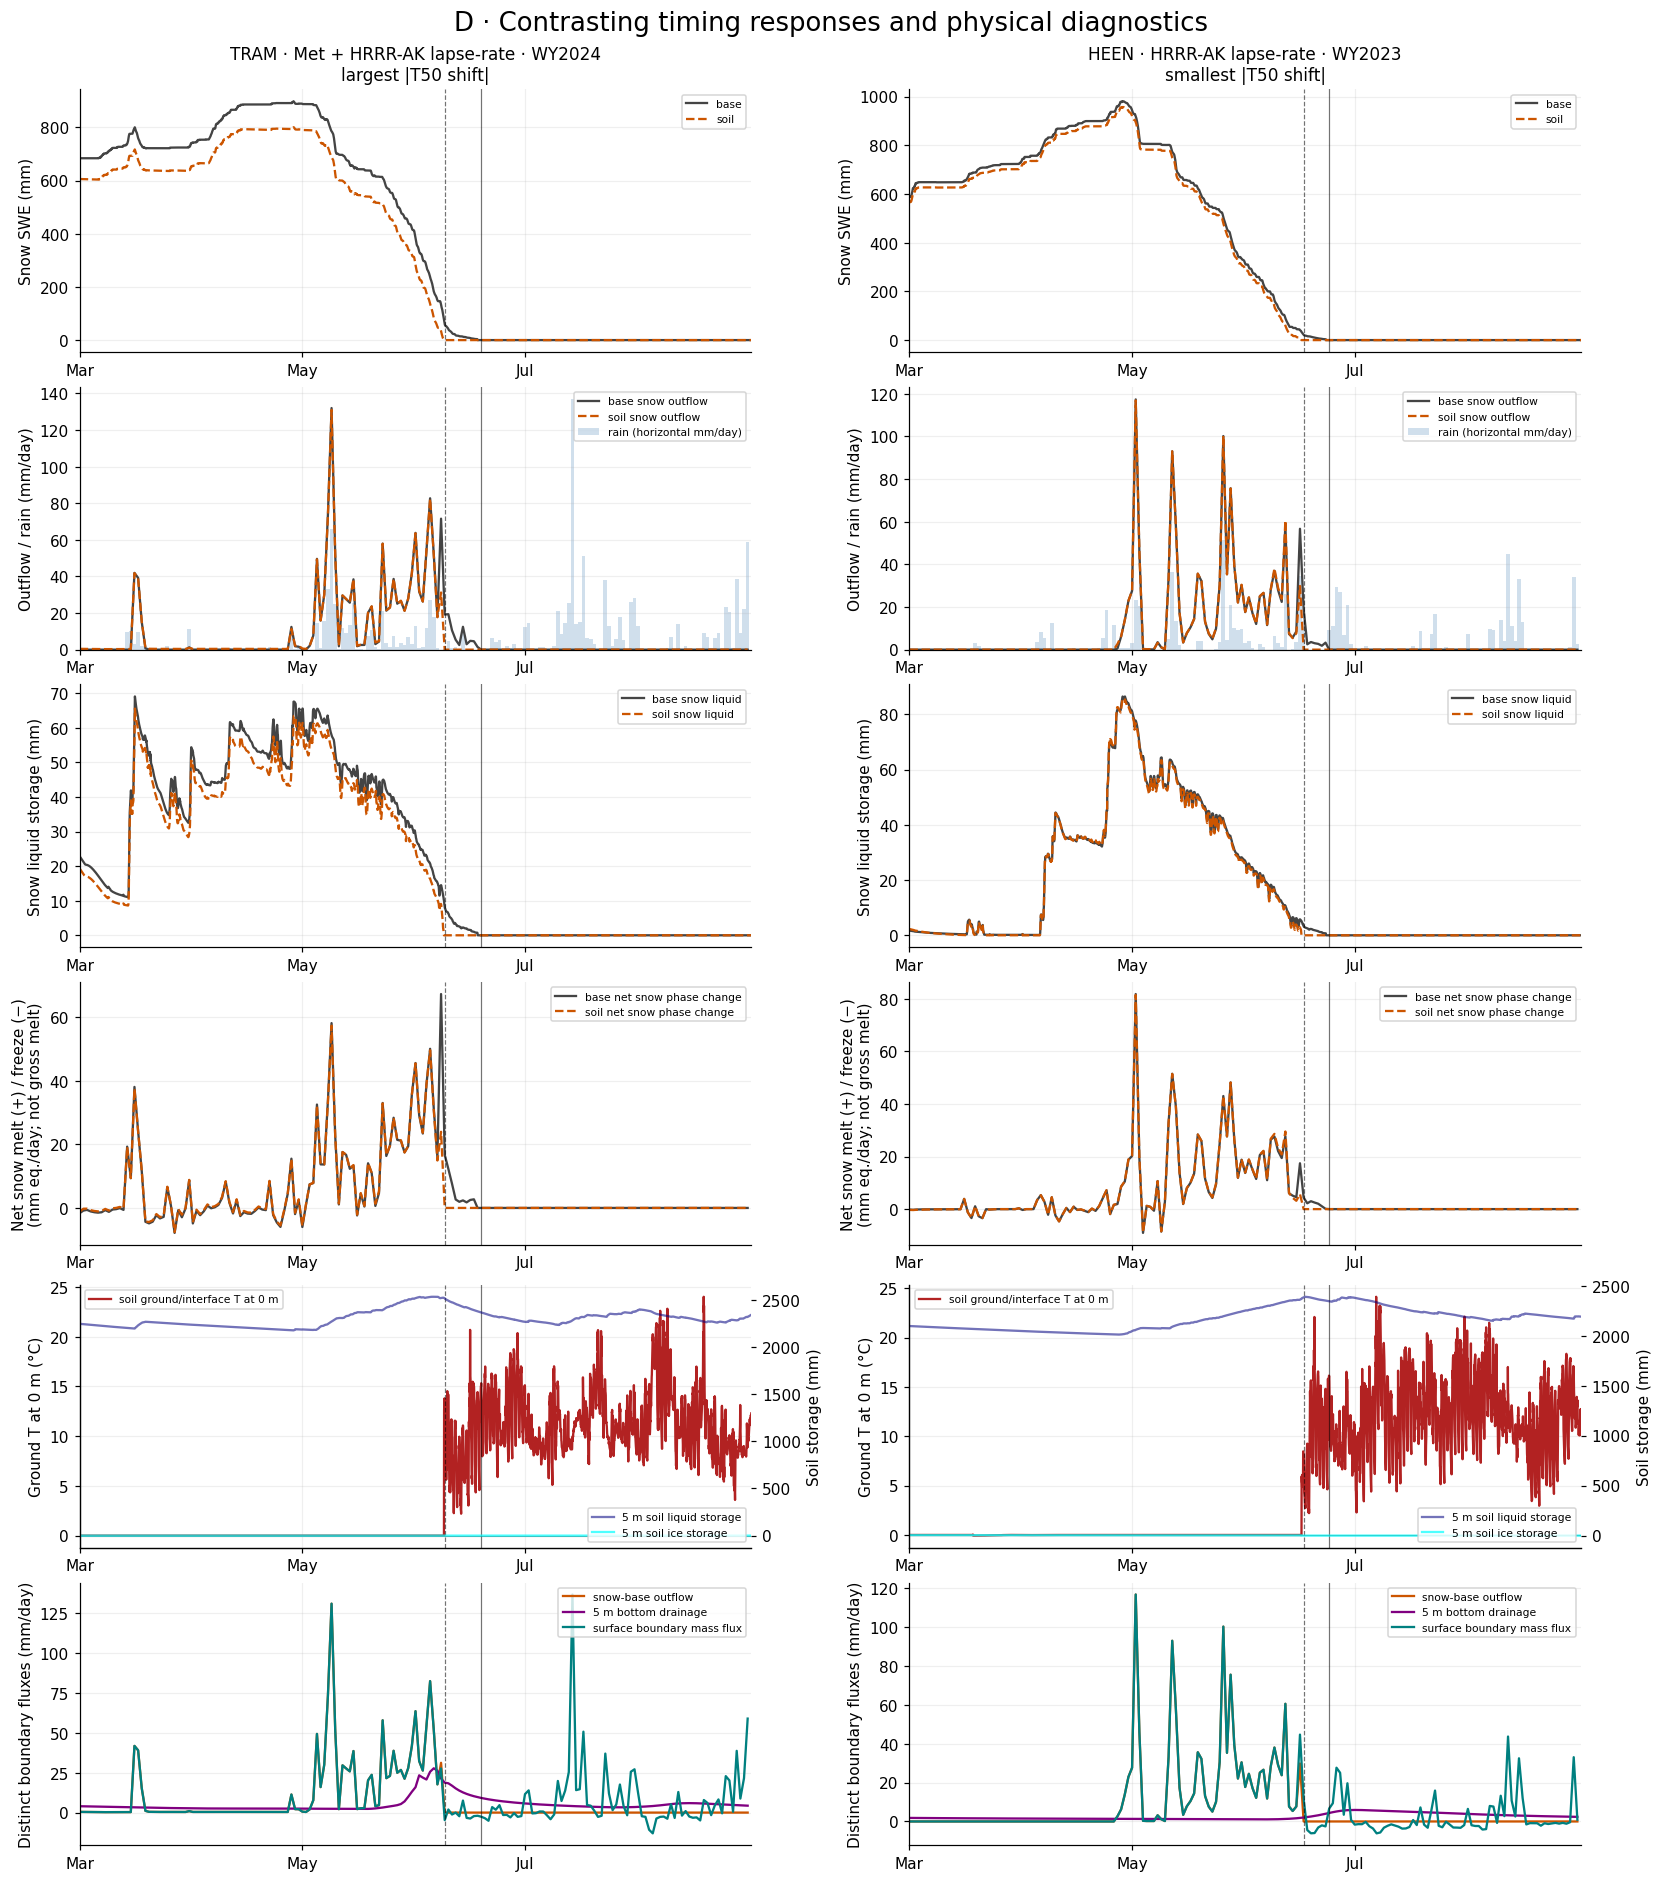

In [8]:
def interval_sum(series,lo,hi):
    q=series.reindex(pd.date_range(lo+pd.Timedelta(hours=1),hi,freq='h'))
    return q.sum() if q.notna().all() else np.nan

balance_rows=[]
for _,r in spring.iterrows():
    lo,hi=bounds(int(r.water_year),'spring')
    for e in ('base','soil'):
        d=pairs[(r.site,r.forcing)][e]
        state0=d.reindex([lo]).iloc[0];state1=d.reindex([hi]).iloc[0]
        terms={name:interval_sum(d[field],lo,hi) for name,field in
               [('snowfall_mm','snowfall_mm'),('rain_on_snow_mm','rain_on_snow_mm'),('evap_signed_mm','snow_evap_signed_mm'),
                ('subl_signed_mm','snow_subl_signed_mm'),('outflow_mm','outflow_mm'),('erosion_mm','erosion_mm'),
                ('surface_boundary_mm','MS_Surface_Mass_Flux'),('bottom_drainage_mm','MS_Soil_Runoff')]}
        delta_swe=state1.SWE-state0.SWE
        residual=terms['snowfall_mm']+terms['rain_on_snow_mm']+terms['evap_signed_mm']+terms['subl_signed_mm']-terms['outflow_mm']-terms['erosion_mm']-delta_swe
        delta_soil=(state1.MS_Water_Soil+state1.MS_Ice_Soil)-(state0.MS_Water_Soil+state0.MS_Ice_Soil)
        balance_rows.append(dict(site=r.site,forcing=r.forcing,water_year=r.water_year,experiment=e,
            delta_SWE_mm=delta_swe,snow_residual_mm=residual,delta_soil_storage_mm=delta_soil,
            partial_soil_residual_mm=terms['surface_boundary_mm']-terms['bottom_drainage_mm']-delta_soil,**terms))
balances=pd.DataFrame(balance_rows);balances.to_csv(OUT/'water_balance_diagnostics.csv',index=False)
eligible=spring[spring.paired_complete & ~spring.incomplete_water_year & ~spring.initialization_sensitive].dropna(subset=['delta_t50_days']).copy()
eligible['absolute_shift']=eligible.delta_t50_days.abs()
ordered=eligible.sort_values(['absolute_shift','site','forcing','water_year'])
selected=pd.concat([ordered.tail(1).assign(contrast='largest |T50 shift|'),ordered.head(1).assign(contrast='smallest |T50 shift|')])
selected.to_csv(OUT/'selected_diagnostic_cases.csv',index=False)
physical_rows=[]
for _,r in selected.iterrows():
    lo,hi=bounds(int(r.water_year),'spring')
    for e in ('base','soil'):
        d=pairs[(r.site,r.forcing)][e]
        window=d.loc[(d.index>lo)&(d.index<=hi)]
        phase_positive=window.net_snow_phase_mm.clip(lower=0)
        phase_stats=summarize(d.net_snow_phase_mm.clip(lower=0),lo,hi)
        physical_rows.append(dict(site=r.site,forcing=r.forcing,water_year=r.water_year,experiment=e,
            SWE_at_Mar1_mm=d.SWE.reindex([lo]).iloc[0],
            net_snow_phase_sum_mm=window.net_snow_phase_mm.sum(min_count=1),
            positive_hourly_net_phase_sum_mm=phase_positive.sum(min_count=1),
            positive_net_phase_T50=phase_stats['t50'],
            liquid_snow_storage_max_mm=window.MS_Water.max(),
            ground_T0_min_C=window.ground_T_C.min(),ground_T0_max_C=window.ground_T_C.max(),
            soil_ice_max_mm=window.MS_Ice_Soil.max(),soil_bottom_drainage_mm=window.MS_Soil_Runoff.sum(min_count=1)))
physical=pd.DataFrame(physical_rows);physical.to_csv(OUT/'selected_case_physics.csv',index=False)
display(physical)

display(selected[['site','forcing','water_year','contrast','delta_total_mm','delta_t50_days','delta_disappearance_days']])
display(balances[['site','forcing','water_year','experiment','snow_residual_mm','partial_soil_residual_mm']].round(2))

def daily_total(s):
    # Shift interval ends by 1 ns so midnight belongs to the preceding day.
    s=s.copy();s.index=s.index-pd.Timedelta(nanoseconds=1)
    return s.resample('D').sum(min_count=24)

fig,axes=plt.subplots(6,len(selected),figsize=(15,17),layout='constrained',squeeze=False)
for col,(_,r) in enumerate(selected.iterrows()):
    site,forcing,wy=r.site,r.forcing,int(r.water_year);lo,hi=bounds(wy,'spring')
    # Show the common spring window, not a different window centered on each simulation's melt.
    a,b=pairs[(site,forcing)]['base'].loc[lo:hi],pairs[(site,forcing)]['soil'].loc[lo:hi]
    for e,d,color,ls in [('base',a,'#444444','-'),('soil',b,'#CC5500','--')]:
        axes[0,col].plot(d.index,d.SWE,color=color,ls=ls,label=e)
        q=daily_total(d.outflow_mm.iloc[1:]);axes[1,col].plot(q.index,q,color=color,ls=ls,label=f'{e} snow outflow')
        axes[2,col].plot(d.index,d.MS_Water,color=color,ls=ls,label=f'{e} snow liquid')
        phase=daily_total(d.net_snow_phase_mm.iloc[1:]);axes[3,col].plot(phase.index,phase,color=color,ls=ls,label=f'{e} net snow phase change')
    rain=daily_total(a.rain_mm.iloc[1:]);axes[1,col].bar(rain.index,rain,color='steelblue',alpha=.25,width=1,label='rain (horizontal mm/day)')
    axes[4,col].plot(b.index,b.ground_T_C,color='firebrick',label='soil ground/interface T at 0 m')
    axes[4,col].axhline(0,color='gray',lw=.7)
    storage=axes[4,col].twinx();storage.plot(b.index,b.MS_Water_Soil,color='navy',alpha=.55,label='5 m soil liquid storage')
    storage.plot(b.index,b.MS_Ice_Soil,color='cyan',alpha=.7,label='5 m soil ice storage');storage.set_ylabel('Soil storage (mm)')
    for field,color,label in [('outflow_mm','#CC5500','snow-base outflow'),('MS_Soil_Runoff','purple','5 m bottom drainage'),('MS_Surface_Mass_Flux','teal','surface boundary mass flux')]:
        q=daily_total(b[field].iloc[1:]);axes[5,col].plot(q.index,q,color=color,label=label)
    for i,ax in enumerate(axes[:,col]):
        for e,ls in [('base','-'),('soil','--')]:
            date=r[f'{e}_disappearance']
            if pd.notna(date):ax.axvline(date,color='black',ls=ls,lw=.8,alpha=.55)
        ax.set_xlim(lo,hi);ax.grid(alpha=.2);ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[3,5,7]));ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
        ax.legend(fontsize=7,loc='upper right')
    axes[0,col].set_title(f'{site.upper()} · {LABELS[forcing]} · WY{wy}\n{r.contrast}',fontsize=11)
    for i,label in enumerate(['Snow SWE (mm)','Outflow / rain (mm/day)','Snow liquid storage (mm)',
                              'Net snow melt (+) / freeze (−)\n(mm eq./day; not gross melt)','Ground T at 0 m (°C)','Distinct boundary fluxes (mm/day)']):axes[i,col].set_ylabel(label)
    h,l=storage.get_legend_handles_labels();axes[4,col].legend(*axes[4,col].get_legend_handles_labels(),loc='upper left',fontsize=7);storage.legend(h,l,loc='lower right',fontsize=7)
fig.suptitle('D · Contrasting timing responses and physical diagnostics',fontsize=17)
savefig(fig,'D_selected_physical_diagnostics');plt.show()


## Paper-facing interpretation and limitations

The cells below calculate statements from the actual paired metrics. “Earlier delivery” refers to T50 of **snowpack outflow within the fixed spring window**, including rain routed through snow. T50 can move when the seasonal volume or which rain events encounter snow changes; it is not by itself a tracer travel time.

Local observation discovery: a filename scan under `/hdd/snow_hydrology` and the project repositories for lysimeter, runoff, streamflow, gauge and discharge files, plus a project-text search for such observations, found no identified local snow-lysimeter or gauged discharge series suitable for validating these point fluxes. This is a scoped discovery result, not proof that no such data exist elsewhere. The existing station snow-depth records support snow presence/disappearance checks, not water-flux validation. A future point snow lysimeter could test snow-base delivery at its location; gauged catchment discharge would require catchment integration/routing and consistent area/unit metadata before comparison. The present results should not be described as changes in basin runoff or observed infiltration.

In [9]:
usable=spring[spring.paired_complete & spring.base_timing_valid & spring.soil_timing_valid].copy()
summary_rows=[]
for (site,forcing),rows in usable.groupby(['site','forcing'],sort=False):
    for label,sub in [('all spring-complete seasons',rows),('excluding first seasons',rows[~rows.initialization_sensitive]),
                      ('complete WY and no first seasons',rows[~rows.initialization_sensitive & ~rows.incomplete_water_year])]:
        if sub.empty:continue
        summary_rows.append(dict(site=site,forcing=forcing,sample=label,n=len(sub),
            median_delta_total_mm=sub.delta_total_mm.median(),median_delta_percent=sub.delta_total_percent.median(),
            median_delta_T50_days=sub.delta_t50_days.median(),min_delta_T50_days=sub.delta_t50_days.min(),max_delta_T50_days=sub.delta_t50_days.max(),
            median_delta_peak24_mm=sub.delta_peak24_mm.median(),median_disappearance_shift_days=sub.delta_disappearance_days.median(),
            earlier_disappearance=int(sub.delta_disappearance_days.lt(0).sum()),
            earlier_T50_with_earlier_disappearance=int((sub.delta_disappearance_days.lt(0)&sub.delta_t50_days.lt(0)).sum())))
summary=pd.DataFrame(summary_rows);summary.to_csv(OUT/'sensitivity_summary.csv',index=False);display(summary.round(3))

text=['## Findings from these simulations']
annual=metrics[(metrics.window=='water_year') & metrics.paired_complete]
text.append(f"- **Window dependence:** across {len(annual)} complete water-year pairs, median volume change is {annual.delta_total_mm.median():.1f} mm ({annual.delta_total_percent.median():.2f}%), compared with {usable.delta_total_mm.median():.1f} mm ({usable.delta_total_percent.median():.2f}%) for spring. These are different samples/windows, not a direct subtraction of medians.")
for label,sub in [('all spring-complete seasons',usable),('excluding first simulated seasons',usable[~usable.initialization_sensitive]),
                  ('complete water years after initialization',usable[~usable.initialization_sensitive & ~usable.incomplete_water_year])]:
    if sub.empty:continue
    earlier=sub[sub.delta_disappearance_days<0]
    text.append(f"- **{label} (n={len(sub)}):** volume difference median {sub.delta_total_mm.median():.1f} mm "
                f"(range {sub.delta_total_mm.min():.1f} to {sub.delta_total_mm.max():.1f}); "
                f"T50 shift median {sub.delta_t50_days.median():.2f} days "
                f"(range {sub.delta_t50_days.min():.2f} to {sub.delta_t50_days.max():.2f}); "
                f"24-hour peak change median {sub.delta_peak24_mm.median():.1f} mm. "
                f"Earlier disappearance coincides with earlier T50 in {int(earlier.delta_t50_days.lt(0).sum())}/{len(earlier)} cases.")
exceptions=usable[(usable.delta_disappearance_days<0)&(usable.delta_t50_days>=0)]
text.append('### Important divergences between disappearance and water delivery')
for _,r in exceptions.iterrows():
    text.append(f"- {r.site.upper()}, {LABELS[r.forcing]}, WY{r.water_year}: disappearance {r.delta_disappearance_days:.1f} days, "
                f"T50 {r.delta_t50_days:.2f} days, volume {r.delta_total_mm:.1f} mm ({r.delta_total_percent:.2f}%).")
if exceptions.empty:text.append('- No reversed-sign T50 cases under this spring-window definition; magnitudes still differ.')
annual_exceptions=annual[(annual.delta_disappearance_days<0)&(annual.delta_t50_days>=0)]
for _,r in annual_exceptions.iterrows():
    text.append(f"- **Water-year exception:** {r.site.upper()}, {LABELS[r.forcing]}, WY{r.water_year}: earlier disappearance {r.delta_disappearance_days:.1f} days but annual T50 {r.delta_t50_days:.2f} days later. Spring and annual T50 are different questions.")
annual_extreme=annual.loc[annual.delta_t50_days.abs().idxmax()]
text.append(f"- The largest absolute annual T50 shift is {annual_extreme.delta_t50_days:.2f} days at {annual_extreme.site.upper()}, {LABELS[annual_extreme.forcing]}, WY{annual_extreme.water_year}; percentile dates can jump between autumn/rain and spring pulses near the 50% threshold, rather than indicating a pulse travel time.")
for _,r in selected.iterrows():
    b=balances[(balances.site==r.site)&(balances.forcing==r.forcing)&(balances.water_year==r.water_year)].set_index('experiment')
    sp=physical[(physical.site==r.site)&(physical.forcing==r.forcing)&(physical.water_year==r.water_year)].set_index('experiment')
    annual_pair=annual[(annual.site==r.site)&(annual.forcing==r.forcing)&(annual.water_year==r.water_year)]
    outside_spring=annual_pair.iloc[0].delta_total_mm-r.delta_total_mm if len(annual_pair) else np.nan
    text.append(f"- **Diagnostic {r.site.upper()} {LABELS[r.forcing]} WY{r.water_year}:** spring outflow change {r.delta_total_mm:.1f} mm; March-1 SWE changes by {sp.loc['soil','SWE_at_Mar1_mm']-sp.loc['base','SWE_at_Mar1_mm']:.1f} mm; rain counted while snow is present changes by {b.loc['soil','rain_on_snow_mm']-b.loc['base','rain_on_snow_mm']:.1f} mm. The same paired water year has {outside_spring:.1f} mm additional soil-minus-base outflow outside March–August. This supports a combination of seasonal redistribution, changed stored snow at spring onset, and changed rain exposure, not only a shift of an identical spring hydrograph.")
    text.append(f"  Peak temporary snow liquid storage: base {sp.loc['base','liquid_snow_storage_max_mm']:.1f} mm, soil {sp.loc['soil','liquid_snow_storage_max_mm']:.1f} mm. Soil ice storage reaches {sp.loc['soil','soil_ice_max_mm']:.1f} mm during this spring window; net phase-change/storage co-variation is diagnostic consistency, not proof of a unique refreezing mechanism.")

reversed_rows=common[common.volume_mm_ranking_reversed]
for _,r in reversed_rows.iterrows():
    text.append(f"- Volume ranking exception on common hours: {r.site.upper()} WY{r.water_year}, mixed minus HRRR changes from {r.base_mixed_minus_hrrr_volume_mm:.1f} mm (base) to {r.soil_mixed_minus_hrrr_volume_mm:.1f} mm (soil); a near-tie can change order even when larger forcing contrasts remain.")
for label,sub in [('all common forcing-years',common),('common forcing-years after initialization',common[~common.initialization_sensitive])]:
    text.append(f"- Forcing ranking reversals among {label}: volume {int(sub.volume_mm_ranking_reversed.sum())}/{len(sub)}, "
                f"T50 {int(sub.T50_days_ranking_reversed.sum())}/{len(sub)} (ties excluded from reversal classification).")
text.append('### Physical support and limits')
text.append(f"- Snow-budget diagnostic residuals over spring: median {balances.snow_residual_mm.median():.2f} mm, "
            f"range {balances.snow_residual_mm.min():.2f} to {balances.snow_residual_mm.max():.2f} mm. "
            'The full signed terms are in water_balance_diagnostics.csv. Residuals and missing terms preclude calling this an independent infiltration estimate.')
soilbal=balances[balances.experiment=='soil']
text.append(f"- Partial soil-boundary residuals: median {soilbal.partial_soil_residual_mm.median():.2f} mm, "
            f"range {soilbal.partial_soil_residual_mm.min():.2f} to {soilbal.partial_soil_residual_mm.max():.2f} mm. "
            'The 5 m drainage series is a separate control-volume exit and can release antecedent water.')
text.append('- Net snow phase change and temporary liquid storage can establish consistency with delayed delivery; they do not isolate gross melt, refreezing, infiltration or a unique causal pathway. No tuning or simulation reruns were performed.')
text.append('- Paper-ready claims are paired-model differences under the stated spring window, area convention and idealized soil treatment. General hydrologic necessity, basin-discharge changes and superiority of the assumed soil profile require flux observations and additional soil/initialization sensitivity experiments.')
interpretation='\n'.join(text)
display(Markdown(interpretation));(OUT/'interpretation.md').write_text(interpretation)
print(f'Outputs: {OUT}')


,site,forcing,sample,n,median_delta_total_mm,median_delta_percent,median_delta_T50_days,min_delta_T50_days,max_delta_T50_days,median_delta_peak24_mm,median_disappearance_shift_days,earlier_disappearance,earlier_T50_with_earlier_disappearance
0,ppsa,hrrr,all spring-complete seasons,6,-103.890,-5.086,-1.896,-2.833,-0.833,-0.241,-6.5,6,6
1,ppsa,hrrr,excluding first seasons,5,-96.024,-4.576,-1.917,-2.833,-0.958,-0.111,-6.0,5,5
2,ppsa,hrrr,complete WY and no first seasons,4,-76.099,-4.161,-1.896,-2.125,-0.958,-0.092,-6.0,4,4
3,ppsa,mixed,all spring-complete seasons,6,-104.384,-5.800,-1.188,-5.042,-0.583,-0.575,-7.0,6,6
4,ppsa,mixed,excluding first seasons,5,-90.787,-5.834,-1.292,-5.042,-0.583,-0.763,-8.0,5,5
5,ppsa,mixed,complete WY and no first seasons,4,-71.869,-4.449,-1.125,-3.167,-0.583,-0.389,-7.0,4,4
6,tram,hrrr,all spring-complete seasons,6,-76.085,-4.017,-0.875,-3.125,-0.250,-0.070,-6.0,6,6
7,tram,hrrr,excluding first seasons,5,-83.874,-4.491,-0.958,-3.125,-0.250,-0.086,-6.0,5,5
8,tram,hrrr,complete WY and no first seasons,4,-97.892,-4.490,-1.292,-3.125,-0.250,0.143,-6.0,4,4
9,tram,mixed,all spring-complete seasons,3,-63.597,-6.008,-1.208,-3.792,-0.375,-0.437,-4.0,3,3


## Findings from these simulations
- **Window dependence:** across 18 complete water-year pairs, median volume change is -42.1 mm (-1.74%), compared with -74.8 mm (-5.01%) for spring. These are different samples/windows, not a direct subtraction of medians.
- **all spring-complete seasons (n=30):** volume difference median -74.8 mm (range -169.2 to -12.5); T50 shift median -1.08 days (range -5.04 to -0.08); 24-hour peak change median -0.3 mm. Earlier disappearance coincides with earlier T50 in 30/30 cases.
- **excluding first simulated seasons (n=24):** volume difference median -74.8 mm (range -169.2 to -12.5); T50 shift median -1.02 days (range -5.04 to -0.08); 24-hour peak change median -0.3 mm. Earlier disappearance coincides with earlier T50 in 24/24 cases.
- **complete water years after initialization (n=18):** volume difference median -74.8 mm (range -146.5 to -13.0); T50 shift median -1.19 days (range -3.79 to -0.25); 24-hour peak change median -0.2 mm. Earlier disappearance coincides with earlier T50 in 18/18 cases.
### Important divergences between disappearance and water delivery
- No reversed-sign T50 cases under this spring-window definition; magnitudes still differ.
- **Water-year exception:** HEEN, HRRR-AK lapse-rate, WY2022: earlier disappearance -7.0 days but annual T50 1.17 days later. Spring and annual T50 are different questions.
- The largest absolute annual T50 shift is -49.04 days at TRAM, Met + HRRR-AK lapse-rate, WY2024; percentile dates can jump between autumn/rain and spring pulses near the 50% threshold, rather than indicating a pulse travel time.
- **Diagnostic TRAM Met + HRRR-AK lapse-rate WY2024:** spring outflow change -102.7 mm; March-1 SWE changes by -78.2 mm; rain counted while snow is present changes by -16.3 mm. The same paired water year has 53.2 mm additional soil-minus-base outflow outside March–August. This supports a combination of seasonal redistribution, changed stored snow at spring onset, and changed rain exposure, not only a shift of an identical spring hydrograph.
  Peak temporary snow liquid storage: base 69.1 mm, soil 65.6 mm. Soil ice storage reaches 0.0 mm during this spring window; net phase-change/storage co-variation is diagnostic consistency, not proof of a unique refreezing mechanism.
- **Diagnostic HEEN HRRR-AK lapse-rate WY2023:** spring outflow change -52.3 mm; March-1 SWE changes by -21.5 mm; rain counted while snow is present changes by -29.3 mm. The same paired water year has 21.5 mm additional soil-minus-base outflow outside March–August. This supports a combination of seasonal redistribution, changed stored snow at spring onset, and changed rain exposure, not only a shift of an identical spring hydrograph.
  Peak temporary snow liquid storage: base 86.5 mm, soil 85.4 mm. Soil ice storage reaches 5.3 mm during this spring window; net phase-change/storage co-variation is diagnostic consistency, not proof of a unique refreezing mechanism.
- Volume ranking exception on common hours: PPSA WY2024, mixed minus HRRR changes from 14.1 mm (base) to -20.5 mm (soil); a near-tie can change order even when larger forcing contrasts remain.
- Forcing ranking reversals among all common forcing-years: volume 1/12, T50 0/12 (ties excluded from reversal classification).
- Forcing ranking reversals among common forcing-years after initialization: volume 1/9, T50 0/9 (ties excluded from reversal classification).
### Physical support and limits
- Snow-budget diagnostic residuals over spring: median 0.01 mm, range -0.31 to 4.71 mm. The full signed terms are in water_balance_diagnostics.csv. Residuals and missing terms preclude calling this an independent infiltration estimate.
- Partial soil-boundary residuals: median 973.53 mm, range 498.41 to 2419.04 mm. The 5 m drainage series is a separate control-volume exit and can release antecedent water.
- Net snow phase change and temporary liquid storage can establish consistency with delayed delivery; they do not isolate gross melt, refreezing, infiltration or a unique causal pathway. No tuning or simulation reruns were performed.
- Paper-ready claims are paired-model differences under the stated spring window, area convention and idealized soil treatment. General hydrologic necessity, basin-discharge changes and superiority of the assumed soil profile require flux observations and additional soil/initialization sensitivity experiments.

Outputs: /home/cassie/python/repos/snow_modeling_point/figures/soil_runoff_comparison
